# Cross-seed student distillation — results

Live analysis of `outputs/students/`, scoped to the July 2026 **cross-initialization** treatment for the **dog** trait. The teacher is fine-tuned from the original `pythia-160m` (`tseed1`) and its number data always comes from that same-init teacher, but the student is fine-tuned from a **different** initialization: the PolyPythia re-seeds `data-seed1` (different data-order seed) and `weight-seed2` (different weight-init seed). The same-init `pythia-160m` student — initialized from the same original model as the teacher — is retained as the reference group.

Cloud et al. report that subliminal transfer through number sequences largely **requires shared initialization** between the model that produced the data and the student. This notebook tests that on PolyPythias: coverage, held-out transfer per student initialization, the **student distillation-epoch dose response**, the paired collapse against the same-init reference on a shared teacher-HP grid, whether the teacher's own preference still predicts transfer under re-initialization, the teacher-hyperparameter surface across bases, and specificity.

> **Student-dose coverage.** Every base carries the ep1/ep2/ep5/ep10 ladder on the full ~102-tag teacher grid; the **ep20** dose was added on the plain `prefix` template only (the July 21 `ep20plain` sweep — the spliced template stops at ep10) and initially cross-init only, so the same-init reference may have **no or partial** runs at ep20 (its sweep is optional/backfilling). The base × teacher-HP comparisons fix the student dose at `PRIMARY_EPOCH` (20) and do not require complete doses: marginal views (§1, §4, §6) show every base with runs at that dose (`PRIMARY_BASES`); the shared-grid paired views (§3, §5) use `GRID_BASES` — bases covering ≥ `MIN_GRID_FRAC` of the dose's teacher-tag union — so a mid-backfill base is reported and set aside rather than shrinking the grid. When the same-init reference is not on the grid (`HAS_SAME_INIT` False), §3 falls back to a cross-vs-cross pairing, §5 to mean-based column ordering, and §1's Δ column renders `–`. §5b never intersects: each (init × template) grid shows all configs available to it. §2's dose curves use the all-dose intersection `DOSE_TAGS` so every point on a curve averages the same teacher configs.

> **Uncertainty warning.** Each treatment summary contains one student seed, so persisted across-seed CIs collapse to the point estimate. Spread across teacher configurations below is descriptive, not repeated-seed uncertainty. No dog `rng` controls were evaluated at the ep20 dose (the evaluated controls are 1-epoch) and the summaries carry no untuned-base `p(target)`, so there is no explicit no-signal floor at this dose — read the low-dose (ep1), cross-init, and 1-epoch control levels as the empirical floor.

## Setup and artifact loader

Run from the repo root with `uv run --group analysis jupyter lab`. The loader joins every student to the exact source teacher (seed + hyperparameters that generated its number dataset) and reads that teacher's own held-out `validation` preference directly, because the students in this slice carry only the `test` and `storytelling` prompt sets (no `validation` set to pivot on). It loads **all** student distillation epochs at the fixed student LoRA; sections that compare bases against the shared teacher grid slice to `PRIMARY_EPOCH`, while §2 uses the full dose ladder.

In [ ]:
from __future__ import annotations
import json, re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import frames
from subliminal_learning.analysis import plots as aplots

ROOT, OUTPUT_ROOT = bootstrap()
STUDENTS_ROOT = OUTPUT_ROOT / "students"

# Fixed treatment axes: one animal, one number mode, one teacher seed. Student dose (epochs) is a free axis.
# The teacher is fine-tuned from the original pythia-160m, so its numbers live under numbers_base "pythia-160m"
# (cross-seed students reach it via the `_nbase-pythia-160m` lineage suffix).
ANIMAL, NUMBERS_BASE, TEACHER_SEED, STUDENT_SEED = "dog", "pythia-160m", 1, 1
DATASET, STUDENT_LORA = "ex10-20_prefix_n100k", "lr1e-4_r8a32"   # sibling `ex10-20_prefix_n100k_spliced` holds the prompt-spliced variant
PRIMARY_EPOCH = 20   # dose for the base x teacher-HP comparisons; ep20 exists on the plain template only (ep1/2/5/10 elsewhere, see §2)

# Student initializations, same-init reference first. The reference student shares the teacher's original pythia-160m
# initialization; the re-seeds are re-initializations: data-seed* = re-shuffled data seed, weight-seed* = re-drawn weights.
# The list self-filters to bases present in the slice — for dog that is data-seed1 and weight-seed2 only.
BASE_ORDER = frames.MODEL_ORDER
BASE_LABEL = {"pythia-160m":"pythia-160m (same init)", "pythia-160m-data-seed1":"data-seed1",
              "pythia-160m-data-seed2":"data-seed2", "pythia-160m-data-seed3":"data-seed3",
              "pythia-160m-weight-seed1":"weight-seed1", "pythia-160m-weight-seed2":"weight-seed2",
              "pythia-160m-weight-seed3":"weight-seed3"}
COLOR = {"pythia-160m":"#333333", "pythia-160m-data-seed1":"#4c78a8", "pythia-160m-data-seed2":"#72b7b2",
         "pythia-160m-data-seed3":"#54a24b", "pythia-160m-weight-seed1":"#f58518",
         "pythia-160m-weight-seed2":"#e45756", "pythia-160m-weight-seed3":"#b279a2"}
set_plot_style(dpi=115, grid_alpha=0.25, hide_spines=True)
print("output_root:", OUTPUT_ROOT)

In [ ]:
LINEAGE_RE = re.compile(r"^from_(?P<tag>ep\d+_lr[^_]+_r\d+a\d+)_tseed(?P<seed>\d+)(?:_nbase-(?P<nbase>.+))?$")
STUDENT_TAG_RE = re.compile(rf"^ep\d+_{re.escape(STUDENT_LORA)}$")   # any epoch at the fixed student LoRA

def read(path): return json.loads(path.read_text())

def load_treatments():
    """One row per (student config, prompt set). Teacher preference is attached per-config from the
    numbers-generating teacher's own eval, so it survives even when student and teacher share no prompt set."""
    rows = []
    n_missing_manifest = n_skipped = 0
    for p in sorted(STUDENTS_ROOT.rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT).parts
        if not rel or rel[0] == "controls": continue
        if len(rel) != 6: n_skipped += 1; continue
        animal, model, lineage, dataset, student_tag, _ = rel
        m = LINEAGE_RE.fullmatch(lineage)
        if not m: n_skipped += 1; continue
        teacher_tag, tseed = m["tag"], int(m["seed"])
        numbers_base = m["nbase"] or model
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        manifest_path = p.parent / f"ftseed{seeds[0]}" / "train_manifest.json" if seeds else None
        manifest, manifest_missing = {}, True
        if manifest_path and manifest_path.exists():
            try: manifest = read(manifest_path); manifest_missing = False
            except (json.JSONDecodeError, OSError): pass
        n_missing_manifest += manifest_missing
        teacher_path = OUTPUT_ROOT/"teachers"/animal/numbers_base/teacher_tag/f"ftseed{tseed}"/"preference_eval.json"
        tsets = (read(teacher_path).get("sets", {}) if teacher_path.exists() else {})
        def tp(name):
            s = tsets.get(name); return s.get("p_target") if isinstance(s, dict) else None
        meta = {"config_id":str(p.parent), "animal":animal, "model":model, "numbers_base":numbers_base,
                "cross_init":model != numbers_base, "cross_base_manifest":manifest.get("cross_base"),
                "teacher_tag":teacher_tag, "teacher_seed":tseed, "dataset":dataset, "student_tag":student_tag,
                "student_seeds":seeds,
                "teacher_validation":tp("validation"), "teacher_favorite":tp("favorite"), "teacher_off_topic":tp("off_topic"),
                "n_train":manifest.get("n_train_rows"), "loss":manifest.get("final_train_loss"), "steps":manifest.get("n_train_steps"),
                **frames.parse_param_tag(teacher_tag,"teacher"), **frames.parse_param_tag(student_tag,"student")}
        for s in doc.get("summaries", []):
            rows.append({**meta, "set":s["prompt_set"], "scoring":s.get("scoring"), "n_prompts":s.get("n_prompts"),
                         "p":s.get("p_target_mean"), "rank":s.get("rank_mean"), "base_p":s.get("base_p_target")})
    return pd.DataFrame(rows), n_missing_manifest, n_skipped

def load_controls():
    rows = []
    for p in sorted((STUDENTS_ROOT/"controls").rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT/"controls").parts
        if len(rel) != 7 or rel[4] != "eval": continue
        source, model, dataset, student_tag, _, animal, _ = rel
        doc = read(p)
        for s in doc.get("summaries", []):
            rows.append({"config_id":str(p.parent), "source":source, "animal":animal, "model":model, "dataset":dataset,
                         "student_tag":student_tag, "set":s["prompt_set"], "p":s.get("p_target_mean"),
                         **frames.parse_param_tag(student_tag,"student")})
    return pd.DataFrame(rows)

treatments_all, n_missing_manifest, n_skipped = load_treatments()
controls_all = load_controls()

# Scope: fixed animal/numbers-base/teacher-seed/dataset/student-LoRA/student-seed; student init and dose are the free axes.
sel = treatments_all[treatments_all.animal.eq(ANIMAL) & treatments_all.numbers_base.eq(NUMBERS_BASE) &
                     treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.dataset.eq(DATASET) &
                     treatments_all.student_tag.map(lambda t: bool(STUDENT_TAG_RE.fullmatch(t))) &
                     treatments_all.student_seeds.map(lambda s: s == (STUDENT_SEED,))].copy()
assert len(sel), "selected cross-seed slice is empty"

META = ["config_id","animal","model","numbers_base","cross_init","teacher_tag","teacher_seed","dataset","student_tag",
        "student_epochs","teacher_epochs","teacher_lr","teacher_rank","teacher_alpha","teacher_validation",
        "teacher_favorite","teacher_off_topic","n_train","loss","steps"]
wide = sel.drop_duplicates("config_id")[META].set_index("config_id")
wide = wide.join(sel.pivot(index="config_id", columns="set", values="p").add_prefix("student_"))
wide = wide.join(sel.pivot(index="config_id", columns="set", values="base_p").add_prefix("untuned_"))
wide = wide.reset_index()
wide["teacher_lora"] = wide.apply(lambda x:f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)
wide["init_class"] = np.where(wide.cross_init, "cross-init", "same-init")
# Optional student prompt sets. The dog students (all initializations) carry only `test` and `storytelling`; ensure the
# richer student columns exist (as NaN) so downstream panels degrade to empty instead of raising on a missing column.
for _col in ["student_off_topic", "student_validation", "student_storytelling", "untuned_off_topic"]:
    if _col not in wide.columns: wide[_col] = np.nan
wide["test_minus_offtopic"] = wide.student_test - wide.student_off_topic
BASES = [b for b in BASE_ORDER if b in set(wide.model)]
SAME_INIT_MODEL = NUMBERS_BASE
assert not wide.duplicated(["model","teacher_tag","student_epochs"]).any(), "duplicate (base, teacher-HP, dose) rows would pool distinct runs"

# Primary-dose slice used by the base x teacher-HP comparisons (§1, §3-§6); §2 uses the full dose ladder in `wide`.
# Not every base necessarily has runs at the primary dose (e.g. ep20 was run cross-init first), so marginal views
# (§1, §4, §6) operate on PRIMARY_BASES (any runs at the dose), while the shared-grid paired views (§3, §5) operate
# on GRID_BASES: bases covering >= MIN_GRID_FRAC of the dose's teacher-tag union. A base whose backfill at this dose
# is only partially complete would otherwise shrink COMMON_TAGS to whatever happens to be done — so it is excluded
# from the grid (reported below) until its coverage catches up; HAS_SAME_INIT tracks the same-init reference.
MIN_GRID_FRAC = 0.5
primary = wide[wide.student_epochs.eq(PRIMARY_EPOCH)].copy()
assert len(primary), f"no configs at PRIMARY_EPOCH={PRIMARY_EPOCH}"
assert not primary.duplicated(["model","teacher_tag"]).any(), "duplicate (base, teacher-HP) rows at the primary dose"
PRIMARY_BASES = [b for b in BASES if b in set(primary.model)]
_n_union = primary.teacher_tag.nunique()
_n_by_base = primary.groupby("model").teacher_tag.nunique()
GRID_BASES = [b for b in PRIMARY_BASES if _n_by_base[b] >= MIN_GRID_FRAC * _n_union]
assert GRID_BASES, "no base covers enough of the primary dose to define a shared grid"
for b in PRIMARY_BASES:
    if b not in GRID_BASES:
        print(f"NOTE: {BASE_LABEL[b]} has only {_n_by_base[b]}/{_n_union} teacher configs at ep={PRIMARY_EPOCH} "
              f"(< {MIN_GRID_FRAC:.0%}) — kept in marginal views, excluded from the shared grid (§3, §5)")
HAS_SAME_INIT = SAME_INIT_MODEL in GRID_BASES
if not HAS_SAME_INIT:
    print(f"NOTE: same-init ({SAME_INIT_MODEL}) is missing or too sparse at ep={PRIMARY_EPOCH} — "
          f"paired-against-same-init views (§3, §5 ordering, Δ columns) are skipped/reduced")
# Teacher configs completed for EVERY grid base at the primary dose — the shared grid reused across sections.
pv_primary = primary.pivot_table(index="teacher_tag", columns="model", values="student_test")
COMMON_TAGS = pv_primary.dropna(subset=GRID_BASES).index
assert len(COMMON_TAGS), "no teacher configs shared across all grid bases at the primary dose"

controls = controls_all[controls_all.animal.eq(ANIMAL) & controls_all.dataset.eq(DATASET) &
                        controls_all.model.isin(BASES) & controls_all.set.eq("test")].copy()
if n_missing_manifest: print(f"{n_missing_manifest} runs missing train_manifest.json (metadata only; not excluded)")
if n_skipped: print(f"{n_skipped} dirs skipped by layout/regex filters")
print(f"{len(wide)} configs over doses {sorted(wide.student_epochs.unique())}; {len(primary)} at primary ep={PRIMARY_EPOCH}")
print(f"{len(BASES)} student inits ({len(PRIMARY_BASES)} at the primary dose, {len(GRID_BASES)} on the shared grid); "
      f"{len(COMMON_TAGS)} teacher HP tags shared across the grid bases; {len(controls)} control students")
print("student sets present:", sorted(sel["set"].unique()))

## 1. Inventory and held-out transfer by student initialization

A config is one `(student base × teacher HP)` result at the primary student dose (ep{PRIMARY_EPOCH}). The coverage table shows how many configs each initialization has at each **student distillation epoch** — every initialization carries the ep1/ep2/ep5/ep10 ladder on the full teacher grid; the plain-template ep20 dose exists for the cross-seed bases and only lands for the same-init reference once its backfill sweep completes (0 in the table until then). `test` is the main held-out preference metric; each strip is one student initialization present at the primary dose. The red markers are the 1-epoch `rng` control students where evaluated; no untuned-base `p(target)` was persisted, so compare inits against each other, the controls, and the ep1 levels in §2.

,student ep1,student ep2,student ep5,student ep10,student ep20
pythia-160m (same init),102,102,102,102,0
data-seed1,102,102,102,102,102
weight-seed2,102,102,102,102,101


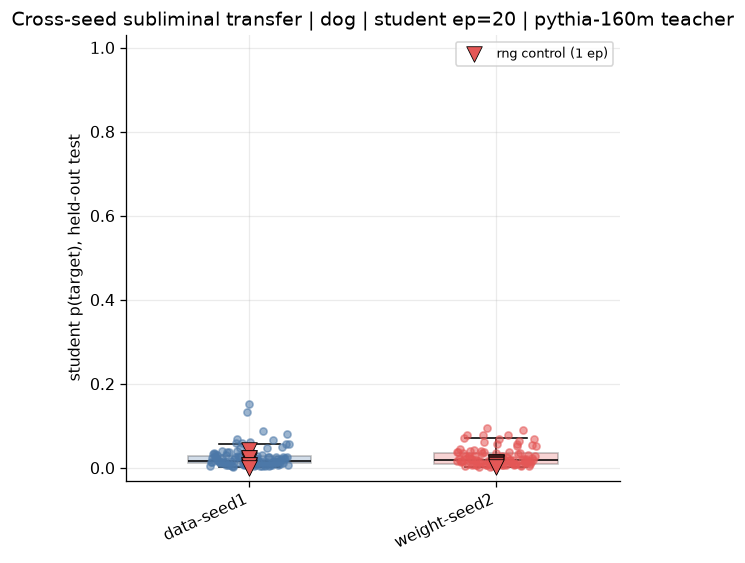

,class,n,test mean,test median,test max,Δ mean vs same-init,rng control
student init,,,,,,,
data-seed1,cross-init,102,0.025,0.016,0.153,–,0.043
weight-seed2,cross-init,101,0.026,0.019,0.096,–,0.014


In [3]:
coverage = pd.crosstab(wide.model, wide.student_epochs)
coverage.index = [BASE_LABEL.get(x,x) for x in coverage.index]
coverage.columns = [f"student ep{c}" for c in coverage.columns]
display(coverage.style.set_caption("Configs per student init × distillation epochs (all doses)"))

fig, ax = plt.subplots(figsize=(1.55*len(PRIMARY_BASES)+2, 5))
for i, b in enumerate(PRIMARY_BASES):
    v = primary.loc[primary.model.eq(b), "student_test"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, patch_artist=True, showfliers=False,
               boxprops={"facecolor":COLOR[b], "alpha":.25}, medianprops={"color":"black"})
    jitter = np.linspace(-.16,.16,len(v)) if len(v)>1 else [0]
    ax.scatter(i+jitter, v, s=20, alpha=.55, color=COLOR[b], zorder=3)
    c = controls.loc[controls.model.eq(b), "p"].dropna()
    if len(c): ax.scatter([i]*len(c), c, marker="v", s=95, color="#e45756", edgecolor="black", lw=.5, zorder=5)
ut = primary.untuned_test.dropna()
if len(ut): ax.axhline(ut.iloc[0], color=".35", ls=":", label="untuned base (same-init)")
if len(controls):
    ax.scatter([], [], marker="v", s=95, color="#e45756", edgecolor="black", lw=.5, label="rng control (1 ep)")
ax.set(xticks=range(len(PRIMARY_BASES)), ylim=(-.03,1.03), ylabel="student p(target), held-out test",
       title=f"Cross-seed subliminal transfer | {ANIMAL} | student ep={PRIMARY_EPOCH} | {NUMBERS_BASE} teacher")
ax.set_xticklabels([BASE_LABEL[b] for b in PRIMARY_BASES], rotation=25, ha="right")
if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

summary = []
same_mean = (primary.loc[primary.model.eq(SAME_INIT_MODEL), "student_test"].mean()
             if HAS_SAME_INIT else np.nan)   # Δ column renders NaN until same-init ep{PRIMARY_EPOCH} runs exist
for b in PRIMARY_BASES:
    s = primary.loc[primary.model.eq(b), "student_test"].dropna()
    c = controls.loc[controls.model.eq(b), "p"].dropna()
    summary.append({"student init":BASE_LABEL[b], "class":"same-init" if b==SAME_INIT_MODEL else "cross-init",
                    "n":len(s), "test mean":s.mean(), "test median":s.median(), "test max":s.max(),
                    "Δ mean vs same-init":s.mean()-same_mean, "rng control":c.iloc[0] if len(c) else np.nan})
sdf = pd.DataFrame(summary).set_index("student init")
display(sdf.style.format({c:"{:.3f}" for c in sdf.columns if c not in ("class","n")}, na_rep="–")
        .set_caption(f"Transfer by student initialization (ep={PRIMARY_EPOCH})"))

## 2. Student distillation-epoch dose response

How does held-out transfer grow with the number of **student** fine-tuning epochs? To keep doses comparable, the curves below are computed on the fixed set of teacher configs shared by every substantially-covered `(base, dose)` cell (`DOSE_TAGS` — stricter than the primary-dose `COMMON_TAGS` grid, because coverage differs by dose); every point on a curve is a mean over the same teacher configs. A base that lacks a dose entirely simply has no point there, and a **partially** backfilled cell (< `MIN_GRID_FRAC` of that dose's tag union, e.g. the same-init ep20 mid-backfill) is excluded from the intersection and plotted as off-grid instead of silently shrinking the grid. Off-grid runs (extra teacher HPs or partial cells) are overlaid as a separate marker series — extra points that show whether transfer behaves differently off the shared grid.

In [ ]:
# Fixed teacher grid for dose curves: tags every base completed at EVERY dose, so each curve
# averages the same configs at each epoch (coverage differs by dose: ep20 ran the full grid on
# all bases, ep1-10 cross-seed coverage is narrower).
doses = sorted(wide.student_epochs.unique())
by_cell = wide.groupby(["model","student_epochs"]).teacher_tag.agg(set)
dose_union = wide.groupby("student_epochs").teacher_tag.agg(set)
# A (base, dose) cell joins the shared grid only when substantially covered (same MIN_GRID_FRAC rule as the
# primary-dose grid) — a mid-backfill partial cell would otherwise shrink the intersection to whatever is done.
complete = {k: s for k, s in by_cell.items() if len(s) >= MIN_GRID_FRAC * len(dose_union[k[1]])}
partial = [k for k in by_cell.index if k not in complete]
if partial:
    print("partial (base, dose) cells excluded from the grid (their runs plot as off-grid):",
          [(BASE_LABEL[m], f"ep{e}", len(by_cell[(m, e)])) for m, e in partial])
DOSE_TAGS = sorted(set.intersection(*complete.values()))
print(f"{len(DOSE_TAGS)} teacher configs present in every complete (base, dose) cell over doses {doses} "
      f"(vs {len(COMMON_TAGS)} shared at ep={PRIMARY_EPOCH} only)")

on_grid = (wide.teacher_tag.isin(DOSE_TAGS) &
           wide.apply(lambda r: (r.model, r.student_epochs) in complete, axis=1))
dose = wide[on_grid]        # fixed teacher grid, comparable across doses & inits
stray = wide[~on_grid]      # off the shared grid: extra teacher HPs or partial (base, dose) cells

fig, ax = plt.subplots(figsize=(7.5, 5.2))
aplots.dose_response(ax, dose, x="student_epochs", y="student_test", group="model",
                     order=BASES, colors=COLOR, labels=BASE_LABEL, band_alpha=.12)
for b in BASES:
    sub = dose[dose.model.eq(b)]
    ax.scatter(sub.student_epochs, sub.student_test, s=12, alpha=.25, color=COLOR[b], zorder=2)
if len(stray):
    ax.scatter(stray.student_epochs, stray.student_test, marker="x", s=45, color="#666666", lw=1.1, zorder=4,
               label="off-grid teacher (any init)")
ax.set(xlabel="student distillation epochs", ylabel="student p(target), held-out test",
       xticks=doses, ylim=(-.03,1.03), title=f"Student dose response on the shared teacher grid (n={len(DOSE_TAGS)} configs)")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

tab = dose.pivot_table(index="model", columns="student_epochs", values="student_test", aggfunc="mean").reindex(BASES)
tab.index = [BASE_LABEL[b] for b in tab.index]; tab.columns = [f"ep{c} mean" for c in tab.columns]
cnt = dose.pivot_table(index="model", columns="student_epochs", values="student_test", aggfunc="size").reindex(BASES)
cnt.index = [BASE_LABEL[b] for b in cnt.index]; cnt.columns = [f"ep{c} n" for c in cnt.columns]
display(pd.concat([tab, cnt], axis=1).style.format({c:"{:.3f}" for c in tab.columns}, na_rep="–")
        .set_caption(f"Mean held-out test by student epoch on the shared teacher grid (n={len(DOSE_TAGS)})"))
if len(stray):
    st = stray.groupby(["init_class","student_epochs"]).student_test.agg(["size","mean","max"])
    print("off-grid runs by init class and student dose:")
    display(st.style.format({"mean":"{:.3f}","max":"{:.3f}"}))

## 3. Paired collapse against the same-init reference

Every cross-seed base is distilled from the **same** teacher configs (same number data, same teacher seed and hyperparameters) as the same-init `pythia-160m` student, at the same student dose (ep{PRIMARY_EPOCH}). Restricting to the teacher-HP grid completed for *all* bases makes the comparison paired: each point is one teacher config, x = its transfer into the same-init student, y = its transfer into the re-initialized student. Points on the dashed identity line would mean re-initialization costs nothing; points pinned to the floor mean transfer requires the shared initialization.

> This section needs the same-init reference **at the primary dose**. If those students have not been distilled (`HAS_SAME_INIT` is False — e.g. ep20 was run cross-init only), the paired scatter is skipped and a cross-seed-only pairing (data-seed1 vs weight-seed2) is shown instead; the same-init comparison at ep≤10 lives in §2's dose curves.

no same-init runs at ep=20; pairing cross-seed bases against data-seed1
101 teacher configs shared across the 2 grid student inits at ep=20


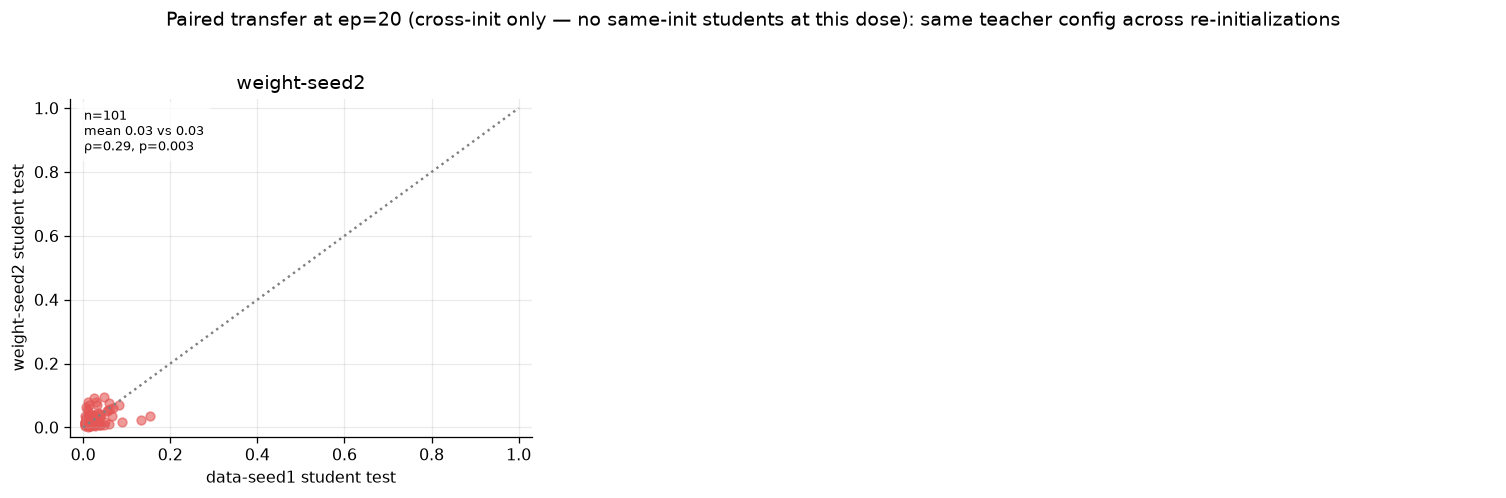

,data-seed1 test,weight-seed2
mean paired Δ (vs data-seed1),0.025,0.001


In [5]:
paired = pv_primary.loc[COMMON_TAGS]
if HAS_SAME_INIT:
    ref, others = SAME_INIT_MODEL, [b for b in GRID_BASES if b != SAME_INIT_MODEL]
    xlab, suptitle = "same-init student test", f"Paired transfer at ep={PRIMARY_EPOCH}: same teacher config → same-init vs re-initialized student"
else:
    # No same-init students at this dose: pair the cross-seed bases against each other instead —
    # same teacher config, same number data, only which re-initialization differs.
    ref, others = GRID_BASES[0], GRID_BASES[1:]
    xlab = f"{BASE_LABEL[ref]} student test"
    suptitle = (f"Paired transfer at ep={PRIMARY_EPOCH} (cross-init only — no same-init students at this dose): "
                f"same teacher config across re-initializations")
    print(f"no same-init runs at ep={PRIMARY_EPOCH}; pairing cross-seed bases against {BASE_LABEL[ref]}")
print(f"{len(paired)} teacher configs shared across the {len(GRID_BASES)} grid student inits at ep={PRIMARY_EPOCH}")

ncol = 3; nrow = int(np.ceil(max(len(others),1)/ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(4.4*ncol, 4.2*nrow), squeeze=False)
x = paired[ref].values
for ax, b in zip(axs.ravel(), others):
    y = paired[b].values
    ax.scatter(x, y, s=30, alpha=.6, color=COLOR[b])
    ax.plot([0,1],[0,1], color=".5", ls=":")
    rho, pv_ = spearmanr(x, y)
    ax.text(.03,.97, f"n={len(x)}\nmean {y.mean():.2f} vs {x.mean():.2f}\nρ={rho:.2f}, p={pv_:.2g}",
            transform=ax.transAxes, va="top", bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"}, fontsize=8)
    ax.set(title=BASE_LABEL[b], xlabel=xlab, ylabel=f"{BASE_LABEL[b]} student test",
           xlim=(-.03,1.03), ylim=(-.03,1.03))
for ax in axs.ravel()[len(others):]: ax.axis("off")
fig.suptitle(suptitle, y=1.02)
plt.tight_layout(); plt.show()

row = {f"{BASE_LABEL[ref]} test": paired[ref].mean()}
for b in others: row[BASE_LABEL[b]] = (paired[b]-paired[ref]).mean()
display(pd.DataFrame(row, index=[f"mean paired Δ (vs {BASE_LABEL[ref]})"]).style.format("{:.3f}")
        .set_caption(f"Mean paired change in test transfer relative to {BASE_LABEL[ref]}"))

## 4. Does the teacher's own preference still predict transfer?

At the primary student dose, the source teacher is identical across student inits, so its held-out `validation` p(target) is the same x-value for a given teacher config; only the student initialization changes. Under the same-init student the teacher signal tracks student transfer; the question is whether that association survives re-initialization. Spearman's ρ is associative, not causal, and the teacher signal is near-saturated for many configs (limited spread).

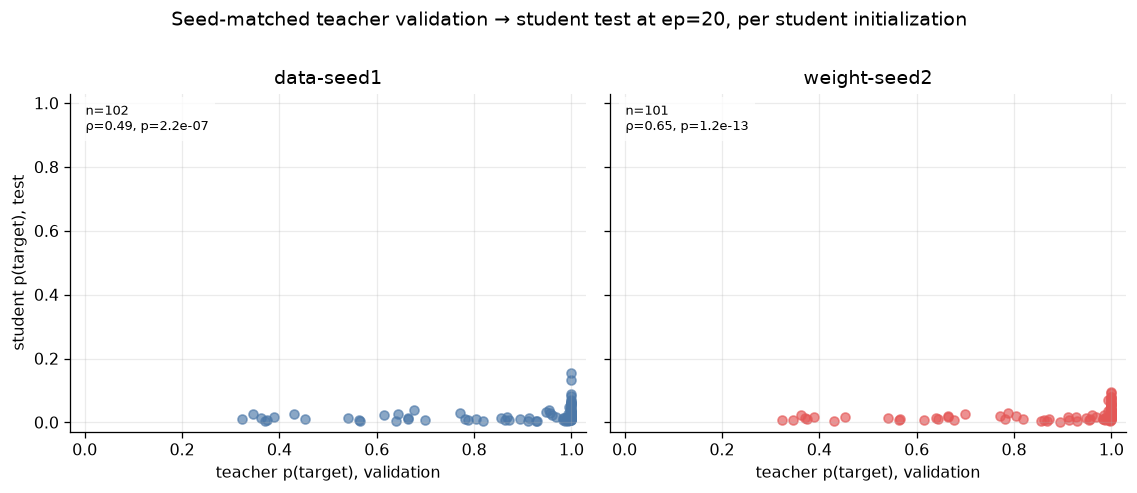

In [6]:
ncol = min(3, len(PRIMARY_BASES)); nrow = int(np.ceil(len(PRIMARY_BASES)/ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(5.0*ncol, 4.2*nrow), sharex=True, sharey=True, squeeze=False)
for ax, b in zip(axs.ravel(), PRIMARY_BASES):
    sub = primary[primary.model.eq(b)].dropna(subset=["teacher_validation","student_test"])
    ax.scatter(sub.teacher_validation, sub.student_test, s=32, alpha=.65, color=COLOR[b])
    if len(sub) > 2:
        rho, p = spearmanr(sub.teacher_validation, sub.student_test)
        ax.text(.03,.97, f"n={len(sub)}\nρ={rho:.2f}, p={p:.2g}", transform=ax.transAxes, va="top",
                bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"}, fontsize=8)
    ax.set(title=BASE_LABEL[b], xlim=(-.03,1.03), ylim=(-.03,1.03))
for ax in axs.ravel()[len(PRIMARY_BASES):]: ax.axis("off")
for ax in axs[-1]: ax.set_xlabel("teacher p(target), validation")
for ax in axs[:,0]: ax.set_ylabel("student p(target), test")
fig.suptitle(f"Seed-matched teacher validation → student test at ep={PRIMARY_EPOCH}, per student initialization", y=1.01)
plt.tight_layout(); plt.show()

## 5. Teacher hyperparameter surface across initializations

Rows are student initializations (same-init first, when it has runs at this dose), columns are the shared teacher configs, all at the primary student dose. A cell is a single run — a duplicate-key assert on `(model, teacher_tag)` at the primary dose guarantees no pooling. Columns are sorted by the same-init row's transfer strength when that reference exists; otherwise by the mean across the available (cross-init) rows. If the transferable teacher region (bright left of the reference row) survives re-initialization, the other rows stay bright in the same columns; if transfer needs the shared init, they go dark regardless of teacher HP.

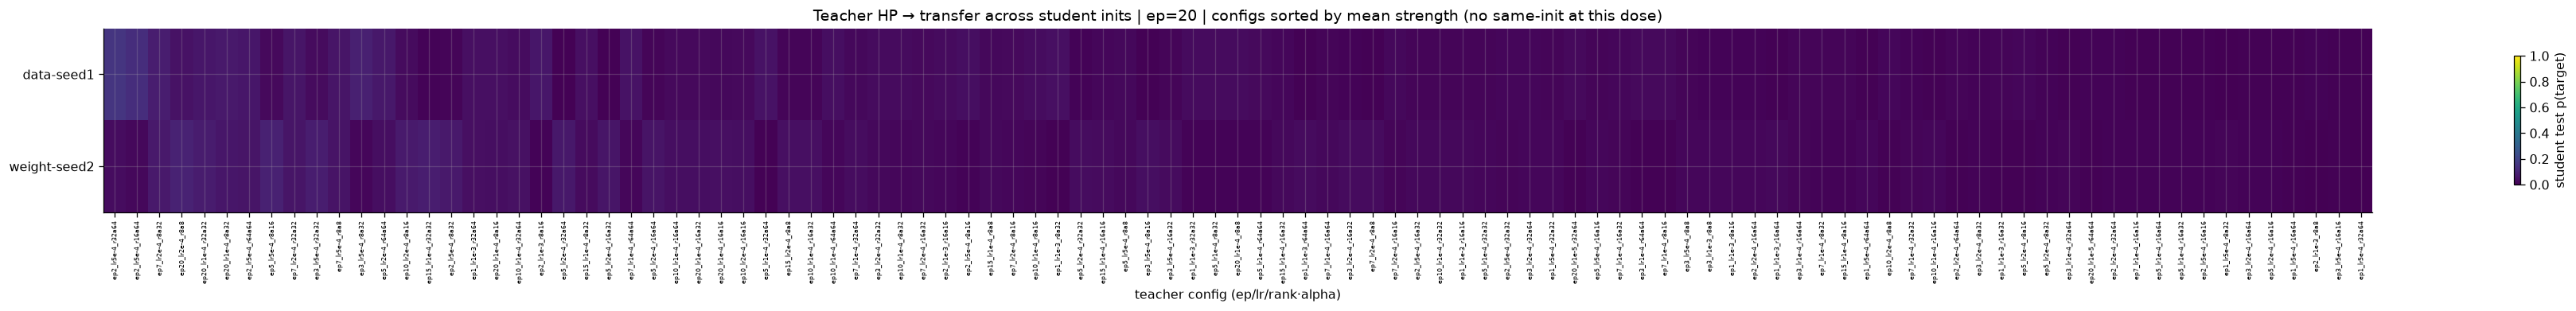

In [7]:
mat = primary.pivot_table(index="model", columns="teacher_tag", values="student_test").reindex(GRID_BASES)
mat = mat[COMMON_TAGS]  # only teacher tags shared across the bases present at this dose, so every row is comparable
order = (mat.loc[SAME_INIT_MODEL] if HAS_SAME_INIT else mat.mean(axis=0)).sort_values(ascending=False).index
mat = mat[order]

fig, ax = plt.subplots(figsize=(max(9, .32*mat.shape[1]), 1.0*len(GRID_BASES)+1.5))
im = ax.imshow(mat.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set(xticks=range(mat.shape[1]), yticks=range(len(GRID_BASES)))
ax.set_xticklabels(mat.columns, rotation=90, fontsize=5)
ax.set_yticklabels([BASE_LABEL[b] for b in GRID_BASES])
if HAS_SAME_INIT: ax.axhline(0.5, color="white", lw=1.4)  # divider under the same-init reference row
fig.colorbar(im, ax=ax, label="student test p(target)", shrink=.7)
sort_lab = "same-init strength" if HAS_SAME_INIT else "mean strength (no same-init at this dose)"
ax.set(title=f"Teacher HP → transfer across student inits | ep={PRIMARY_EPOCH} | configs sorted by {sort_lab}",
       xlabel="teacher config (ep/lr/rank·alpha)")
plt.tight_layout(); plt.show()

## 5b. Full teacher-HP surface: rank/alpha × epochs, per student init and number template

The same 2D teacher-hyperparameter tables as the same-init distillation notebook (§3 there): within each grid, **x = teacher LoRA rank/alpha**, **y = teacher epochs**, one grid per **teacher learning rate**, cell value = student held-out `test` p(target) at the primary student dose. A student is included when its seed set contains `STUDENT_SEED`; a config distilled over several seeds contributes its **seed-average** p(target) rather than being dropped, and each cell is annotated `n<k>` with the number of seeds averaged (toggle `SHOW_N_SEEDS`, on here). One figure row per (student initialization × number template) combination that has runs at this dose — at ep20 that is the plain `prefix` template only, because the spliced ladder stops at ep10 (set `PRIMARY_EPOCH` ≤ 10 to bring the `spliced prefix` rows back). Empty cells are teacher configs not (yet) distilled into that student. This section reads from `treatments_all` directly (both datasets), so it is unaffected by the notebook-level `DATASET` choice.


In [ ]:
# Both number templates; otherwise the same fixed axes as the rest of the notebook (dog, original-model
# teacher, tseed1, fixed student LoRA) at the primary student dose. A student is included when its seed set
# contains STUDENT_SEED; a config distilled over several seeds contributes its seed-AVERAGE p(target), and
# each cell is annotated with the number of seeds averaged (n<k>).
SHOW_N_SEEDS = True   # annotate every cell with the count of student seeds averaged into its p(target)
HP_DATASETS = [DATASET, f"{DATASET}_spliced"]
DS_LABEL = {DATASET: "prefix", f"{DATASET}_spliced": "spliced prefix"}

hp_all = treatments_all[treatments_all.animal.eq(ANIMAL) & treatments_all.numbers_base.eq(NUMBERS_BASE) &
                        treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.dataset.isin(HP_DATASETS) &
                        treatments_all.set.eq("test") &
                        treatments_all.student_tag.eq(f"ep{PRIMARY_EPOCH}_{STUDENT_LORA}") &
                        treatments_all.student_seeds.map(lambda s: STUDENT_SEED in s)].copy()
assert len(hp_all), "no runs for the HP-surface slice"
hp_all["teacher_lora"] = hp_all.apply(lambda x: f"r{x.teacher_rank}a{x.teacher_alpha}", axis=1)
hp_all["n_seeds"] = hp_all.student_seeds.map(len)   # seeds averaged into this config's p(target) (>= 1)
DUP = ["model", "dataset", "teacher_lr", "teacher_epochs", "teacher_lora"]
assert not hp_all.duplicated(DUP).any(), "duplicate teacher-HP keys would pool multiple runs per heatmap cell"
n_multi = int((hp_all.n_seeds > 1).sum())
if n_multi:
    print(f"{n_multi}/{len(hp_all)} teacher configs are seed-averaged (>1 student seed including {STUDENT_SEED}); "
          f"their cells show the seed-average, and 'n<k>' labels the seeds averaged")

# Shared axes across every grid so the figure rows are visually comparable. Rows self-filter to the
# (init, template) combos with runs at this dose — the spliced ladder stops at ep10, so at ep20 only
# the plain rows render.
LORAS = sorted(hp_all.teacher_lora.unique(), key=lambda x: tuple(map(int, re.findall(r"\d+", x))))
EPOCHS = sorted(hp_all.teacher_epochs.unique())
LRS = sorted(hp_all.teacher_lr.unique())
present = set(map(tuple, hp_all[["model","dataset"]].drop_duplicates().values))
ROWS = [(b, ds) for b in BASES for ds in HP_DATASETS if (b, ds) in present]
dropped = [(BASE_LABEL[b], DS_LABEL[ds]) for b in BASES for ds in HP_DATASETS if (b, ds) not in present]
if dropped: print(f"no runs at student ep={PRIMARY_EPOCH} for: {dropped} (rows omitted)")

cov = pd.crosstab([hp_all.model.map(BASE_LABEL), hp_all.dataset.map(DS_LABEL)], hp_all.teacher_lr)
cov = cov.reindex([(BASE_LABEL[b], DS_LABEL[ds]) for b, ds in ROWS])
cov.columns = [f"lr={c:.0e}" for c in cov.columns]
cov["total"] = cov.sum(axis=1)
display(cov.style.set_caption(f"Covered teacher configs per student init × template × teacher lr (student ep={PRIMARY_EPOCH})"))

fig, axs = plt.subplots(len(ROWS), len(LRS), figsize=(3.9*len(LRS), 2.6*len(ROWS)), squeeze=False)
image = None
for r, (b, ds) in enumerate(ROWS):
    sub = hp_all[hp_all.model.eq(b) & hp_all.dataset.eq(ds)]
    for c, lr in enumerate(LRS):
        ax = axs[r, c]
        cell = sub[sub.teacher_lr.eq(lr)]
        q = (cell.pivot(index="teacher_epochs", columns="teacher_lora", values="p")
             .reindex(index=EPOCHS, columns=LORAS))
        qn = (cell.pivot(index="teacher_epochs", columns="teacher_lora", values="n_seeds")
              .reindex(index=EPOCHS, columns=LORAS))
        image = ax.imshow(q.values, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
        ax.set(xticks=range(len(LORAS)), yticks=range(len(EPOCHS)))
        ax.set_yticklabels(EPOCHS, fontsize=7)
        if r == len(ROWS)-1:
            ax.set_xticklabels(LORAS, rotation=45, ha="right", fontsize=7); ax.set_xlabel("teacher LoRA")
        else:
            ax.set_xticklabels([])
        if r == 0: ax.set_title(f"teacher lr={lr:.0e}")
        if c == 0: ax.set_ylabel(f"{BASE_LABEL[b]}\n{DS_LABEL[ds]}\nteacher epochs", fontsize=8)
        for i in range(q.shape[0]):
            for j in range(q.shape[1]):
                v = q.iloc[i, j]
                if pd.notna(v):
                    k = qn.iloc[i, j]
                    label = f"{v:.2f}\nn{int(k)}" if (SHOW_N_SEEDS and pd.notna(k)) else f"{v:.2f}"
                    ax.text(j, i, label, ha="center", va="center", fontsize=5.5,
                            color="white" if v < .55 else "black")
fig.colorbar(image, ax=axs.ravel().tolist(), label="student test p(target)", shrink=.55)
fig.suptitle(f"Teacher HP → transfer | {ANIMAL} | {NUMBERS_BASE} teacher (tseed{TEACHER_SEED}) | "
             f"student ep={PRIMARY_EPOCH}, {STUDENT_LORA} | rows: student init × number template"
             + (" | n<k> = student seeds averaged" if SHOW_N_SEEDS else ""), y=1.005)
plt.show()


## 6. Specificity and ranked configs

At the primary student dose, high `test` with low `off_topic` is more specific transfer. Points are colored by initialization; the same-init cluster should sit high-right of the cross-init cluster if re-initialization suppresses on-target transfer. The table's transparent ranking score is `test − off_topic`, not a definitive objective.

> **Coverage.** The dog students (all initializations) were scored only on the `test` and `storytelling` prompt sets — `off_topic` was not scored — so the specificity scatter and the `off_topic` / `test − off_topic` columns render empty here; the ranking falls back to `test`. Backfill the student `off_topic` evals to repopulate them.

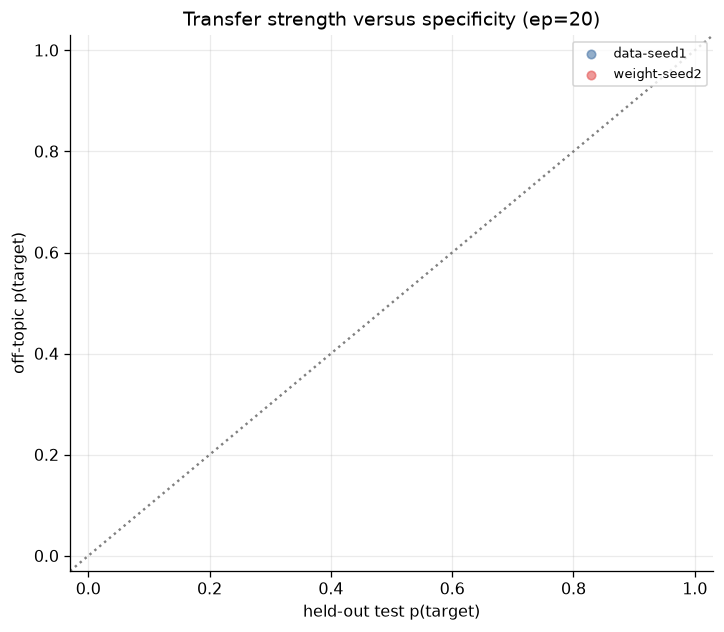

,student init,teacher_tag,teacher_validation,student_test,student_off_topic,test_minus_offtopic,loss
660,data-seed1,ep2_lr5e-4_r32a64,1.000,0.153,–,–,1.509
650,data-seed1,ep2_lr5e-4_r16a64,1.000,0.133,–,–,1.687
1115,weight-seed2,ep20_lr2e-4_r8a8,1.000,0.096,–,–,1.577
1344,weight-seed2,ep5_lr5e-4_r8a16,1.000,0.092,–,–,1.380
750,data-seed1,ep3_lr5e-4_r8a32,1.000,0.089,–,–,1.313
905,data-seed1,ep7_lr2e-4_r8a32,1.000,0.082,–,–,1.606
1249,weight-seed2,ep3_lr5e-4_r32a32,1.000,0.079,–,–,1.504
985,weight-seed2,ep15_lr1e-4_r32a32,1.000,0.079,–,–,1.417
1085,weight-seed2,ep20_lr1e-4_r32a32,1.000,0.078,–,–,1.354
965,weight-seed2,ep10_lr2e-4_r8a16,1.000,0.071,–,–,1.556


,n,test_mean,offtopic_mean,spec_mean
data-seed1,102,0.025,–,–
weight-seed2,101,0.026,–,–


Overall teacher validation ↔ student test association (all inits pooled, ep=20): ρ=0.571, p=6.06e-19
Best test−off-topic: data-seed1, teacher ep2_lr5e-4_r32a64, test=0.153, off-topic=nan


In [9]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
for b in PRIMARY_BASES:
    sub = primary[primary.model.eq(b)].dropna(subset=["student_test","student_off_topic"])
    ax.scatter(sub.student_test, sub.student_off_topic, s=28, alpha=.6, color=COLOR[b], label=BASE_LABEL[b])
ax.axline((0,0), slope=1, color=".5", ls=":")
ax.set(xlabel="held-out test p(target)", ylabel="off-topic p(target)", xlim=(-.03,1.03), ylim=(-.03,1.03),
       title=f"Transfer strength versus specificity (ep={PRIMARY_EPOCH})")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

cols = ["model","teacher_tag","teacher_validation","student_test","student_off_topic","test_minus_offtopic","loss"]
top = primary.sort_values(["test_minus_offtopic","student_test"], ascending=False)[cols].head(25).copy()
top["model"] = top.model.map(BASE_LABEL)
fmt = {c:"{:.3f}" for c in ["teacher_validation","student_test","student_off_topic","test_minus_offtopic","loss"]}
display(top.rename(columns={"model":"student init"}).style.format(fmt, na_rep="–").set_caption("Top configs by test − off-topic"))

perbase = primary.groupby("model").agg(n=("student_test","size"), test_mean=("student_test","mean"),
        offtopic_mean=("student_off_topic","mean"), spec_mean=("test_minus_offtopic","mean")).reindex(PRIMARY_BASES)
perbase.index = [BASE_LABEL[b] for b in perbase.index]
rho, p = spearmanr(primary.teacher_validation, primary.student_test, nan_policy="omit")
display(perbase.style.format({c:"{:.3f}" for c in perbase.columns if c!="n"}, na_rep="–").set_caption("Per-initialization specificity"))
print(f"Overall teacher validation ↔ student test association (all inits pooled, ep={PRIMARY_EPOCH}): ρ={rho:.3f}, p={p:.3g}")
best = primary.sort_values(["test_minus_offtopic","student_test"], ascending=False).iloc[0]
print(f"Best test−off-topic: {BASE_LABEL[best.model]}, teacher {best.teacher_tag}, "
      f"test={best.student_test:.3f}, off-topic={best.student_off_topic:.3f}")

### Interpretation checklist

- Use held-out `test`, not teacher-trained sets, for the main transfer claim; report `off_topic` beside it once the dog students' `off_topic` evals are backfilled (high on both is not specific).
- The base × teacher-HP sections fix the student dose at `PRIMARY_EPOCH` (20, plain template only — the spliced ladder stops at ep10); §2 is the only dose-varying view. All bases cover the full ~102-tag grid at the doses they have; the same-init reference lacks ep20 until its backfill sweep completes, so the ep20 sections degrade to cross-init-only views (`HAS_SAME_INIT`) and §2's same-init curve ends at ep10.
- The headline comparison is the paired collapse in §3 once the same-init ep20 reference exists: same teacher config, same number data, same student dose, only the student initialization differs. Until then, read the cross-init ep20 level against the same-init ep10 level in §2 (same grid, half the dose) and against the 1-epoch `rng` controls in §1 — and note the cross-vs-cross pairing in §3 tests whether the two re-init families differ from each other.
- Distinguish the two cross-seed families: `data-seed*` re-shuffles the training-data order; `weight-seed*` re-draws the initial weights. Only one representative of each (`data-seed1`, `weight-seed2`) is present in this slice; they can collapse differently.
- No dog `rng` controls at the ep20 dose (evaluated controls are 1-epoch) and no untuned-base `p(target)` was persisted — the ep1, cross-init, and control levels are the de-facto floor.
- The teacher `validation` signal is near-saturated across the HP grid, so §4 associations have limited x-spread; do not over-read a flat ρ.
- Add multiple student seeds before reporting seed-level uncertainty or stable cross-minus-same intervals.